# HK vs SK on the DSNB with a spectral fit and sidebands

NB03 compared HK and SK with a window-only treatment (15.5–29.5 MeV, one tagged neutron). Its two limits, statistics only and Gaussian background constraints, differed by a factor of ≈ 2 in significance. The real SK analysis is an **extended likelihood fit over six regions** (Sec. VII of [arXiv:2109.11174](https://arxiv.org/abs/2109.11174)): three Cherenkov-angle ranges × (one / not one tagged neutron), 15.5–79.5 MeV, with free atmospheric normalisations. The sidebands fix the backgrounds in the signal region.

This notebook builds a binned version of that fit (`spectral.py`) and repeats the HK vs SK comparison.

**Public code.** The DSNB spectral-analysis code CARNE (Y. Ashida et al., [github.com/yashida1207/CARNE](https://github.com/yashida1207/CARNE), MIT, poster #37 at Neutrino 2026) was checked. As of its last push (June 2026) it is a prototype: an unbinned likelihood with toys over the signal window, with SK-IV inputs from Figs. 18 and 24 (the same numbers as our CSV files). It has no sidebands, and its package is not yet functional. So the fit is written here.

Parts:
- **1. Templates from Fig. 26**
- **2. Validation against SK**
- **3. HK reach and when HK matches SK**
- **4. Why neutron tagging matters less here**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from hk_sunu import hk, sk4, skgd, spectral as sp

INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e6e5df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "figure.figsize": (7.2, 4.4), "figure.dpi": 110, "font.size": 11,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "legend.frameon": False,
})
EXPOSURE_SK4 = skgd.FIDUCIAL_KTON * sk4.LIVETIME_DAYS / 365.25  # kton yr
HORIUCHI_FLUX = sk4.HORIUCHI09_FLUX  # cm^-2 s^-1, E_nu > 17.3 MeV

# 1. Templates from Fig. 26

Fig. 26 of the SK-IV paper shows the best-fit spectra of every category in the six regions as vector curves. They were extracted with PyMuPDF (`scripts/extract_sk4_fig26.py`) and sampled at the centres of 32 bins of 2 MeV, 15.5–79.5 MeV (`data/sk4_fig26_bestfit.csv`).

| Region | Tagged neutrons | θ_C |
|---|---|---|
| I, II, III | exactly 1 | 20–38°, 38–50°, 78–90° |
| IV, V, VI | ≠ 1 | same |

Two checks:
- **Category totals** compared with the best-fit numbers of Table XIV.
- **The DSNB curve in region II** compared with the Horiuchi+09 prediction of Fig. 24 (15.5–29.5 MeV). Their ratio is the SK-IV best-fit signal strength; the templates are divided by it so that μ = 1 means Horiuchi+09 (6 MeV, max), 1.94 cm⁻²s⁻¹ above 17.3 MeV.

category    Fig. 26  Table XIV
decaye        157.9      169.5
nuecc         109.8      109.9
ncqe           92.3       88.2
mupi           28.4       27.9
spall          10.0

SK-IV best-fit DSNB / Horiuchi+09 (region II, 15.5-29.5 MeV): 1.56


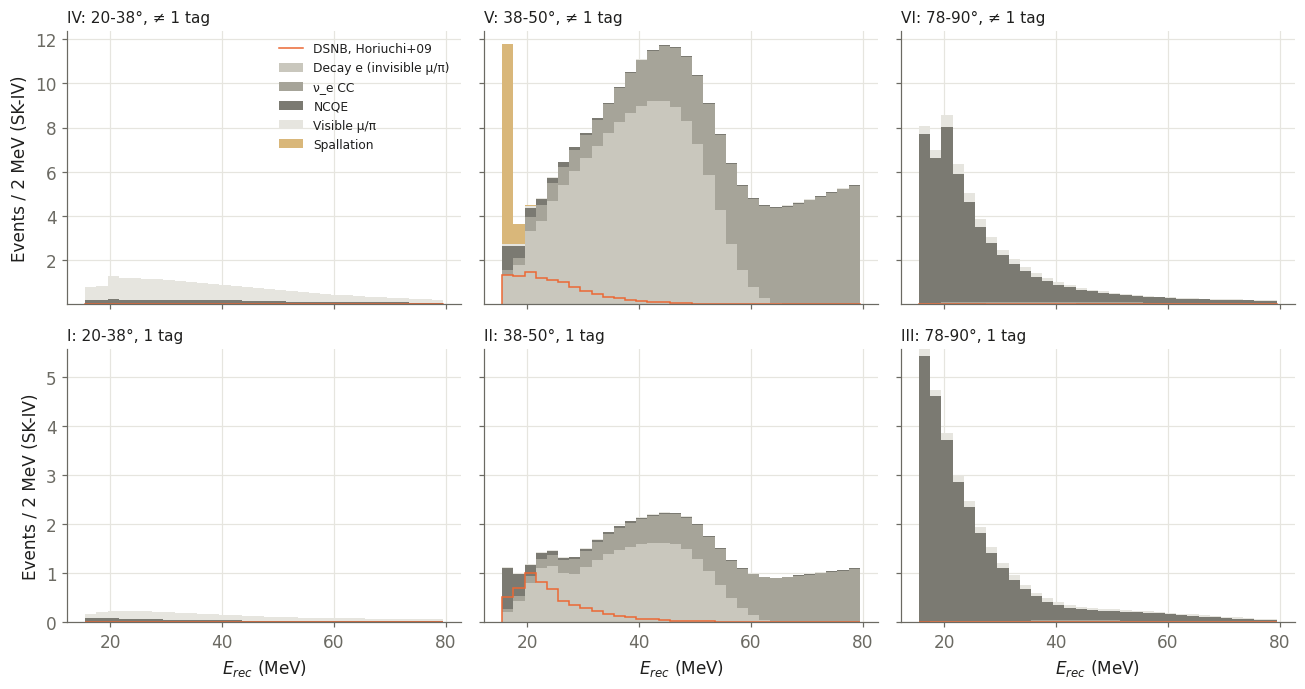

In [2]:
raw = sp._read_fig26()
table_xiv = {"decaye": 169.5, "nuecc": 109.9, "ncqe": 88.2, "mupi": 27.9}
print(f"{'category':10} {'Fig. 26':>8} {'Table XIV':>10}")
for key, ref in table_xiv.items():
    print(f"{key:10} {raw[key].sum():8.1f} {ref:10.1f}")
print(f"{'spall':10} {raw['spall'].sum():8.1f}")
print(f"\nSK-IV best-fit DSNB / Horiuchi+09 (region II, 15.5-29.5 MeV): {sp.horiuchi_scale():.2f}")

tmpl = sp.templates()
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey="row")
labels = {"decaye": "Decay e (invisible μ/π)", "nuecc": "ν_e CC", "ncqe": "NCQE", "mupi": "Visible μ/π", "spall": "Spallation"}
edges = np.arange(15.5, 80.0, 2.0)
for i, ax in enumerate(axes.flat):
    region = [3, 4, 5, 0, 1, 2][i]
    bottom = np.zeros(sp.CENTRES.size)
    for key, color in zip(sp.BACKGROUNDS, ["#c9c7bd", "#a6a499", "#7b7a72", "#e6e5df", "#d9b77a"]):
        ax.bar(edges[:-1], tmpl[key][region], width=2.0, bottom=bottom, align="edge", color=color, label=labels[key])
        bottom += tmpl[key][region]
    ax.stairs(tmpl["dsnb"][region], edges, color=SERIES[1], label="DSNB, Horiuchi+09")
    ax.set_title(f"{sp.REGIONS[region]}: {['20-38°', '38-50°', '78-90°'][region % 3]}, "
                 f"{'1 tag' if region < 3 else '≠ 1 tag'}", loc="left", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("$E_{rec}$ (MeV)")
for ax in axes[:, 0]:
    ax.set_ylabel("Events / 2 MeV (SK-IV)")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

Decay electrons come out 7% below Table XIV; the other categories agree within 5%. The steep rise below 20 MeV (spallation in region V, decay-e in region II) is where the sampling at bin centres is least accurate. The DSNB ratio to Fig. 24 is constant within ±5% bin to bin, so the shapes agree.

Caveats of the templates:
- They are **best-fit** spectra, not the nominal expectations. Background normalisations differ from the predictions by up to 23% (Table XIV); this matters little because they are free in the fit.
- **Accidental coincidences** are not a separate category: they are inside the one-tag templates. To scale them, the fraction of accidentals in the one-tag background is taken per bin from Fig. 24 (region II) and applied to regions I–III.

## 1.1 The fit

Binned Poisson likelihood over 6 regions × 32 bins:
- signal strength μ;
- one free normalisation per background category (decay-e, ν_e CC, NCQE, μ/π, spallation);
- one migration pull per atmospheric category, moving events between one-tag and ≠ 1-tag regions at constant total, with a 1σ width of 40% (Sec. VII C of the SK paper).

The shape uncertainties of the spallation, ν_e CC and NCQE spectra are neglected; SK quotes about 5% on the limits from them.

Median significance and limits use the Asimov dataset with the profile likelihood. Datasets of several phases are combined bin by bin with shared normalisations.

# 2. Validation against SK

In [3]:
def sk_phase(days, phase=None):
    x = skgd.FIDUCIAL_KTON * days / 365.25 / EXPOSURE_SK4
    if phase is None:
        return sp.project(x)
    sc = skgd.scenario(phase)
    return sp.project(x, sc.efficiency_scale[4:], sc.mistag_scale[4:])

def sk_at(year):
    lt = skgd.livetimes_at(year)
    return sp.combine(sk_phase(lt["pure_water"]), sk_phase(lt["SK-VI"], "SK-VI"), sk_phase(lt["SK-VII"], "SK-VII"))

sk4_t = sk_phase(sk4.LIVETIME_DAYS)
ul = sp.asimov_upper_limit(sk4_t)
sigma = ul / 1.2816
print("SK-IV, 2970 d")
print(f"  model : sigma_mu = {sigma:.2f}, Z(mu=1) = {sp.asimov_significance(sk4_t):.2f}")
print(f"  paper : expected 90% UL 2.2 cm^-2 s^-1 (Bayesian, flat prior) -> sigma_mu ~ {2.2 / 1.645 / HORIUCHI_FLUX:.2f}")

gd = sp.combine(sk_phase(skgd.LIVETIME_DAYS["SK-VI"], "SK-VI"), sk_phase(skgd.LIVETIME_DAYS["SK-VII"], "SK-VII"))
print("SK-VI + VII, 956 d")
print(f"  model : sigma_mu = {sp.asimov_upper_limit(gd) / 1.2816:.2f}")
print(f"  paper : best fit 1.4 (+1.5 -1.2) cm^-2 s^-1 for 1.9 predicted -> sigma_mu ~ {1.4 / 1.9:.2f}")

sk26 = sk_at(2026.5)
print("SK-IV to VIII, June 2026 (5002 d)")
print(f"  model : Z(mu=1) = {sp.asimov_significance(sk26):.2f}")
print(f"  SK    : 3.6 +1.6/-1.5 for 3.9 predicted (E_nu > 13.3 MeV) -> expected ~ {3.9 / 1.55:.1f} sigma; observed 2.6 sigma")

SK-IV, 2970 d
  model : sigma_mu = 0.61, Z(mu=1) = 1.61
  paper : expected 90% UL 2.2 cm^-2 s^-1 (Bayesian, flat prior) -> sigma_mu ~ 0.69
SK-VI + VII, 956 d


  model : sigma_mu = 0.92
  paper : best fit 1.4 (+1.5 -1.2) cm^-2 s^-1 for 1.9 predicted -> sigma_mu ~ 0.74
SK-IV to VIII, June 2026 (5002 d)
  model : Z(mu=1) = 2.29
  SK    : 3.6 +1.6/-1.5 for 3.9 predicted (E_nu > 13.3 MeV) -> expected ~ 2.5 sigma; observed 2.6 sigma


The model reproduces SK within ≈ 10–25%:
- **SK-IV** σ_μ is ≈ 10% smaller than the paper's (the paper's 90% limit is Bayesian and includes efficiency systematics).
- **SK-Gd 956 d** is ≈ 25% worse than the paper: the model scales SK-IV templates and does not use the SK-Gd improvements in the sidebands.
- **SK June 2026**: Z ≈ 2.3 against ≈ 2.5 expected from the quoted error, even without the 11.5–15.5 MeV bins that the 2026 analysis added.

This is much better than the window-only treatment of NB03 (1.3σ with systematics, 1.9σ statistics only, for the same SK dataset). **This fit replaces both NB03 treatments.**

# 3. HK reach and when HK matches SK

HK is SK-IV scaled to 187 kton per livetime year, with the spallation of NB02 ($f_{sp}$ = 6.5, and 13 as in the HK poster) and the tagging scenarios of NB02/NB03, now applied to the six regions:

| | r (one-tag efficiency) | k (accidentals) |
|---|---|---|
| A, SK-IV BDT (HK baseline) | 1 | 1 |
| B, degraded | 0.75 | 3 |
| C, pessimistic | 0.5 | 10 |
| G*, SK-Gd-like (not HK) | SK-VII / SK-IV | SK-VII / SK-IV |

Signal and real-neutron events not tagged once move to the ≠ 1 regions; extra accidentals are only added to the one-tag regions. HK starts in mid-2028 with an 80% duty factor. SK plans as in NB03: SK-a (no data after June 2026) and SK-b (data through 2028).

SK-a, no more data        : Z = 2.29
SK-b, data to end of 2028 : Z = 2.51


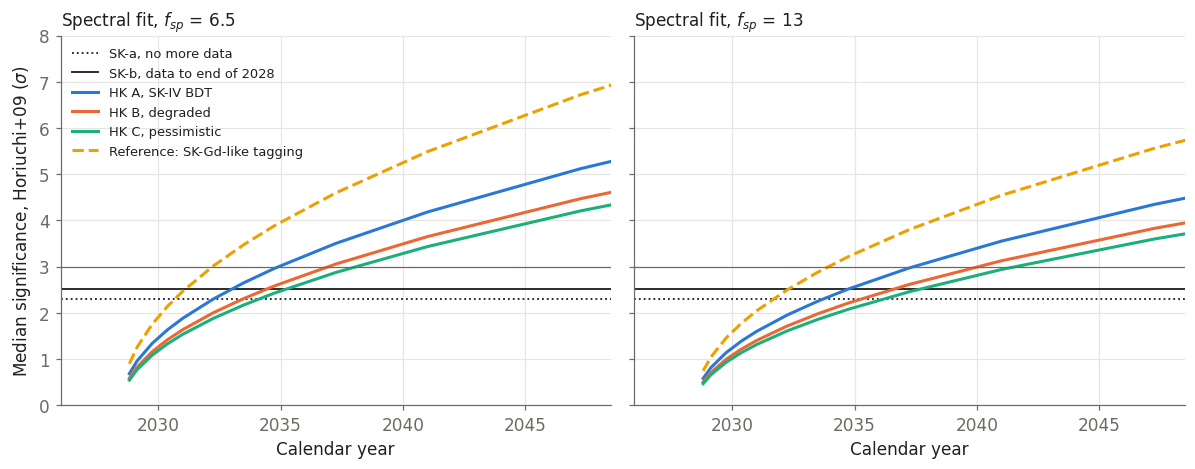

In [4]:
vii = skgd.scenario("SK-VII")
HK_SCEN = {
    "A": ("A, SK-IV BDT", 1.0, 1.0),
    "B": ("B, degraded", 0.75, 3.0),
    "C": ("C, pessimistic", 0.5, 10.0),
    "G": ("G*, SK-Gd-like", vii.efficiency_scale[4:], vii.mistag_scale[4:]),
}
DUTY, HK_START = 0.8, 2028.5

def hk_t(key, live_years, f_sp=6.5):
    _, r, k = HK_SCEN[key]
    return sp.project(live_years * hk.FIDUCIAL_KTON / EXPOSURE_SK4, r, k, f_sp)

def z_hk(key, live_years, f_sp=6.5):
    return sp.asimov_significance(hk_t(key, live_years, f_sp))

SK_PLANS = {"SK-a, no more data": 2026.5, "SK-b, data to end of 2028": 2029.0}
z_sk = {label: sp.asimov_significance(sk_at(year)) for label, year in SK_PLANS.items()}
for label, z in z_sk.items():
    print(f"{label:26}: Z = {z:.2f}")

years = np.array([0.25, 0.5, 1, 1.5, 2, 3, 4, 5, 7, 10, 15, 20])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
z_curves = {}
for ax, f_sp in zip(axes, (6.5, 13.0)):
    for (label, _), ls in zip(SK_PLANS.items(), (":", "-")):
        ax.axhline(z_sk[label], color=INK, ls=ls, lw=1.2, label=label)
    for (key, (name, _, _)), color in zip(HK_SCEN.items(), SERIES):
        z = np.array([z_hk(key, t, f_sp) for t in years])
        z_curves[(key, f_sp)] = z
        ax.plot(HK_START + years / DUTY, z, color=color, ls="--" if key == "G" else "-",
                label=f"HK {name}" if key != "G" else "Reference: SK-Gd-like tagging")
    ax.axhline(3, color=MUTED, lw=0.8)
    ax.set(xlim=(2026, 2048.5), ylim=(0, 8), xlabel="Calendar year", xticks=range(2030, 2050, 5))
    ax.set_title(f"Spectral fit, $f_{{sp}}$ = {f_sp:g}", loc="left", fontsize=11)
axes[0].set_ylabel("Median significance, Horiuchi+09 ($\\sigma$)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()

In [5]:
def crossing(key, target, f_sp):
    z = z_curves[(key, f_sp)]
    if z[-1] < target:
        return np.nan
    return brentq(lambda t: z_hk(key, t, f_sp) - target, 0.05, years[-1])

print("HK livetime years (calendar date) to match SK, and to reach 3 sigma")
header = [f"{label.split(',')[0]}, f_sp={f:g}" for f in (6.5, 13.0) for label in SK_PLANS] + ["3σ, f_sp=6.5", "3σ, f_sp=13"]
print(f"{'':16}" + "".join(f"{h:>22}" for h in header))
for key, (name, _, _) in HK_SCEN.items():
    row = f"{name:16}"
    for target_list in ([(z_sk[l], f) for f in (6.5, 13.0) for l in SK_PLANS] + [(3.0, 6.5), (3.0, 13.0)]):
        t = crossing(key, *target_list)
        row += f"{t:12.1f} ({HK_START + t / DUTY:6.1f})" if np.isfinite(t) else f"{'> 20 yr':>22}"
    print(row)
print("(G* is not an HK scenario: HK tags neutrons on hydrogen only)")
print("\nZ after 10 and 20 livetime years:")
for key, (name, _, _) in HK_SCEN.items():
    print(f"  {name:16} f_sp=6.5: {z_hk(key, 10):.1f}, {z_hk(key, 20):.1f}   f_sp=13: {z_hk(key, 10, 13):.1f}, {z_hk(key, 20, 13):.1f}")

HK livetime years (calendar date) to match SK, and to reach 3 sigma
                        SK-a, f_sp=6.5        SK-b, f_sp=6.5         SK-a, f_sp=13         SK-b, f_sp=13          3σ, f_sp=6.5           3σ, f_sp=13


A, SK-IV BDT             3.0 (2032.2)         3.6 (2033.0)         4.1 (2033.7)         5.0 (2034.7)         5.1 (2034.9)         7.1 (2037.4)


B, degraded              3.9 (2033.4)         4.7 (2034.4)         5.4 (2035.2)         6.4 (2036.5)         6.8 (2036.9)         9.2 (2040.0)


C, pessimistic           4.4 (2034.1)         5.3 (2035.2)         6.1 (2036.1)         7.3 (2037.6)         7.6 (2038.0)        10.4 (2041.5)


G*, SK-Gd-like           1.7 (2030.6)         2.1 (2031.1)         2.5 (2031.6)         3.0 (2032.3)         3.0 (2032.2)         4.3 (2033.9)
(G* is not an HK scenario: HK tags neutrons on hydrogen only)

Z after 10 and 20 livetime years:
  A, SK-IV BDT     f_sp=6.5: 4.2, 5.9   f_sp=13: 3.6, 5.0


  B, degraded      f_sp=6.5: 3.7, 5.2   f_sp=13: 3.1, 4.4
  C, pessimistic   f_sp=6.5: 3.4, 4.9   f_sp=13: 2.9, 4.2
  G*, SK-Gd-like   f_sp=6.5: 5.5, 7.8   f_sp=13: 4.5, 6.4


# 4. Why neutron tagging matters less here

In the window-only analysis (NB03) the tagging scenario changed the HK crossing time by a factor of ≈ 10 between A and C. With the spectral fit the scenarios are much closer. Two reasons:
- **Untagged signal is not lost**: it moves to region V (≠ 1 tag, 38–50°), whose background above ≈ 20 MeV is dominated by decay electrons and ν_e CC, both well constrained by their shapes and sidebands.
- **Accidentals only hurt region II**, which is one region out of six.

The cost of SK-IV-like tagging is mainly at the lowest energies, where region V is dominated by spallation. The contributions per region show it:

In [6]:
def z_regions(t, keep):
    sub = {key: v[keep] for key, v in t.items()}
    return sp.asimov_significance(sub)

for name, t in [("SK-IV 2970 d", sk4_t), ("HK A, 10 yr", hk_t("A", 10)), ("HK C, 10 yr", hk_t("C", 10))]:
    print(f"{name:14}: all {sp.asimov_significance(t):.2f} | one-tag only (I-III) {z_regions(t, slice(0, 3)):.2f} "
          f"| != 1 only (IV-VI) {z_regions(t, slice(3, 6)):.2f}")

SK-IV 2970 d  : all 1.61 | one-tag only (I-III) 1.21 | != 1 only (IV-VI) 1.02
HK A, 10 yr   : all 4.18 | one-tag only (I-III) 3.24 | != 1 only (IV-VI) 2.63
HK C, 10 yr   : all 3.43 | one-tag only (I-III) 1.01 | != 1 only (IV-VI) 3.28


In SK-IV the ≠ 1 regions alone carry a sensitivity comparable to the one-tag regions. This is consistent with the SK-I–III analyses, without neutron tagging, which reached a sensitivity similar to SK-IV's.

# 5. Conclusions

- **The binned spectral fit reproduces SK** within 10–25% (SK-IV, SK-Gd, and the June 2026 expected significance of ≈ 2.3–2.5σ). It replaces the two window-only treatments of NB03.
- **HK, with tagging on hydrogen only, matches SK after ≈ 3–5 livetime years in A (2032–2035), 4–6 in B and 4.5–7 in C (2034–2038)**; the lower values are for SK-a with $f_{sp}$ = 6.5, the higher for SK-b with $f_{sp}$ = 13. The spread between A and C is now a factor ≈ 1.5, not ≈ 10 as in NB03.
- **HK reaches 3σ for Horiuchi+09 after ≈ 5–7 livetime years in A (2035–2037)** and ≈ 8–10 in C; 10 years give 3.6–4.2σ in A and 2.9–3.4σ in C.
- **The spallation level matters as much as the tagging scenario**: going from $f_{sp}$ = 6.5 to 13 costs about as much as going from A to C.
- **Neutron tagging on hydrogen matters less than the window-only analysis suggested**, because the untagged signal still counts in the ≠ 1 regions. What matters is the background shape knowledge in those regions, especially spallation below ≈ 20 MeV.

Caveats:
- Templates are SK-IV best-fit curves sampled at bin centres; HK detector effects (resolution, PID with 20% coverage) are assumed equal to SK-IV.
- The HK spallation treatment scales both the SK-IV spallation template (× $f_{sp}$) and the cost of the SK-IV cut. The HK poster instead assumes a residual of 13 × SK with an SK-like cut efficiency, so $f_{sp}$ = 13 here is conservative: it applies both.
- Shape systematics are neglected; normalisations are free; one migration pull per atmospheric category (40%).
- The signal is Horiuchi+09 6 MeV max (≈ the SK 2026 best fit). For a smaller flux the significances drop roughly in proportion.